In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/paysim.csv")
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:
print(df["isFraud"].value_counts())
print(f"Taux de fraude : {df['isFraud'].mean() * 100:.3f} %")

isFraud
0    6354407
1       8213
Name: count, dtype: int64
Taux de fraude : 0.129 %


In [3]:
pd.crosstab(df["type"], df["isFraud"])

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


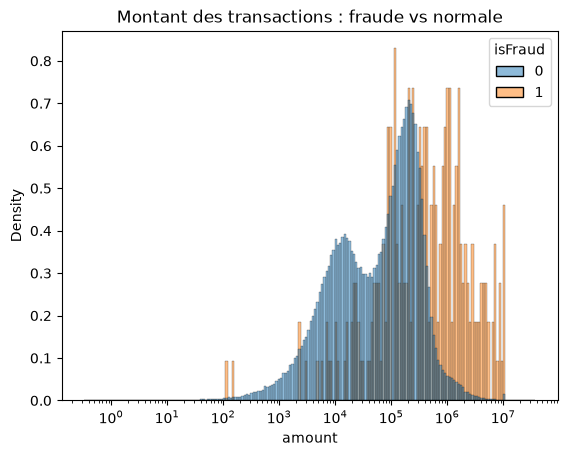

In [4]:
sns.histplot(data=df.sample(200_000, random_state=42), x="amount",
             hue="isFraud", log_scale=True, stat="density", common_norm=False)
plt.title("Montant des transactions : fraude vs normale")
plt.show()